# **Monte Carlo Analysis of Train-Delay Propagation on a Suburban Railway Line**

**SE4042 – Modelling and Simulation of Sciences | Individual Assignment 1**

This project investigates how initial train delays, stochastic station dwell times and timetable recovery buffers affect delay propagation and the probability of significant delays across a simplified Maradana → Panadura suburban railway corridor. Five services and six stations common to the supplied timetables are modelled using a discrete-time Markov chain for operating-disruption regimes and Monte Carlo simulation for uncertainty and sensitivity analysis. The scheduled times are based on the Sri Lanka Railways timetables. Delay-transition probabilities and random disturbance parameters are explicitly treated as illustrative assumptions because route-specific train-level operational records were not available.



## **2. Problem and research question**

### 2.1 Problem description

Train delays can propagate along a railway route. A delay at one station may affect the next station's arrival and departure times, while additional dwell-time and running-time disturbances can increase or reduce the delay. Recovery time in the timetable may help absorb some of these disturbances. This project represents these mechanisms on a simplified Maradana → Panadura corridor.

### 2.2 Research question

**How do initial train delays, stochastic station dwell times and timetable recovery buffers affect delay propagation and the probability of significant delays across a simplified suburban railway line?**

### 2.3 Project scope

The model represents five Maradana → Panadura services using the six stations common to the five supplied timetables. It uses a Markov chain to represent a simplified operating-disruption regime and Monte Carlo replications to investigate uncertainty and sensitivity. Additional stops shown in some services are excluded from this first common-station comparison.


## **3. Model, assumptions and equations**

### 3.1 Data sources and provenance (X4 – Real-Data Grounding)

The scheduled times are transcribed from the Sri Lanka Railways Coastal Line timetable notice and the five Maradana → Panadura timetables.

The official Sri Lanka Railways Administration Report 2023 includes monthly system-wide passenger-train punctuality summaries. Its annual summary reports 34.11% in the “right time (included below 5 min delay)” category, 14.25% in the 1–10 minute category, and 51.62% in the over-10-minute category. These are **reported system-wide categories**, not observations for the five trains in this model; category labels are quoted as published rather than reinterpreted as station-level states.

The Auditor General's 2024 report states that 58,693 operated services (49%) were delayed between 10 and 60 minutes, and 5,305 planned services were cancelled. These figures also cover the wider railway system, not this particular route or timetable.

These official sources ground the importance and broad context of the problem. They do not provide the train-level sequences needed to estimate the Markov transition matrix, dwell-time distributions or running-time noise. Therefore, this notebook does not claim that the stochastic parameters are calibrated from aggregate statistics.

**Important evidence distinction:** the timetable is real schedule data; the transition probabilities, regime shocks, running-time noise, dwell-time distribution and minimum headway used by the simulation are illustrative assumptions, not measured service-level parameters. Results describe this simplified model and must not be presented as validated predictions of actual Maradana–Panadura delays.

### 3.2 Model assumptions and parameters

- The five services are processed in scheduled order.
- The initial-delay scenario applies the same extra departure delay to every service at Maradana; this is a controlled system-wide stress scenario, not a measured event.
- Operating conditions are represented by three latent regimes: Low, Moderate and High. These are **not observed official delay classes**.
- The transition matrix and regime disturbance ranges are assumed.
- Running-time disturbances are sampled from a zero-mean normal distribution.
- Extra dwell time at intermediate stations is sampled from an exponential distribution.
- A simplified minimum departure headway is enforced at each departure station.
- A recovery-buffer parameter is subtracted in the arrival-delay update.
- The destination station has an arrival time only.

### 3.3 Mathematical model


For train $i$ at station $s$, let $d^D_{i,s}$ be the departure delay. The arrival delay at the next station is:

$$
d^A_{i,s+1} = \max\left(0,\ d^D_{i,s} + \epsilon_{i,s} + q_{z_{i,s+1}} - b\right)
$$

where $d^A_{i,s+1}$ is the arrival delay at the next station, $d^D_{i,s}$ is the departure delay at the current station, $\epsilon_{i,s}$ is the zero-mean running-time disturbance, $z_{i,s+1}$ is the next Markov operating regime, $q_{z_{i,s+1}}$ is the non-negative disturbance associated with that regime, and $b$ is the recovery-buffer parameter.

The Markov regime changes according to:

$$
P(z_{i,s+1}=j\mid z_{i,s}=k)=p_{kj}
$$

where $P=[p_{kj}]$ is a row-stochastic transition matrix.

At an intermediate station, the additional dwell time is:

$$
W_{i,s}\sim\operatorname{Exponential}(\text{mean}=\mu_W)
$$

and the actual departure time is:

$$
D^{\mathrm{act}}_{i,s}
=
\max\left(
D^{\mathrm{sch}}_{i,s},
A^{\mathrm{act}}_{i,s}+W^{\mathrm{sch}}_{i,s}+W_{i,s}
\right)
$$

The simplified minimum departure-headway constraint is:

$$
D^{\mathrm{act}}_{i,s}
\geq
D^{\mathrm{act}}_{i-1,s}+h
$$

where $h$ is the assumed minimum headway and $i-1$ is the preceding service.


### 3.4 Module topics demonstrated

1. **Discrete-event simulation / queueing ideas:** services are processed in timetable order and a minimum departure headway is enforced.
2. **Input modelling and random variate generation:** stochastic running-time and dwell-time disturbances are generated using normal and exponential distributions.
3. **Discrete-time Markov chains:** the operating-disruption regime changes between Low, Moderate and High states using a transition matrix.
4. **Monte Carlo simulation and uncertainty:** repeated operating-period simulations, confidence intervals and sensitivity analysis are used to estimate model outcomes.


## **4. Implementation**

The following cells implement the model described in Section 3. Run the notebook from top to bottom. The master random seed supports reproducibility. The notebook uses Python with NumPy, pandas and Matplotlib; no external files or paid services are required for the simulation.


### 4.1 Environment and reproducibility
The master seed makes each notebook run reproducible. No external files or paid services are required.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MASTER_SEED = 20261028
rng = np.random.default_rng(MASTER_SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Master seed:", MASTER_SEED)

NumPy: 2.4.6
Pandas: 2.2.3
Master seed: 20261028


### 4.2 Baseline timetable dataset
Times are represented as minutes after 05:00. These are the six stations common to the five supplied services.

In [16]:
stations = ["Maradana", "Colombo Fort", "Dehiwala",
            "Ratmalana", "Moratuwa", "Panadura"]
train_ids = ["T1_0505", "T2_0552", "T3_0628", "T4_0700", "T5_0750"]

# All values are minutes after 05:00.
# Rows = trains; columns = stations.
# NaN means arrival/departure is not applicable at origin/destination.
scheduled_arrival = np.array([
    [np.nan, 10, 25, 33, 41, 53],    # T1: 05:05
    [np.nan, 56, 76, 84, 94, 107],   # T2: 05:52
    [np.nan, 92, 112, 120, 130, 143],# T3: 06:28
    [np.nan, 124, 145, 151, 158, 171],# T4: 07:00
    [np.nan, 174, 196, 204, 214, 227],# T5: 07:50
], dtype=float)

scheduled_departure = np.array([
    [5, 11, 26, 34, 42, np.nan],     # T1
    [52, 57, 77, 85, 95, np.nan],    # T2
    [88, 93, 113, 121, 131, np.nan], # T3
    [120, 125, 146, 152, 159, np.nan],# T4
    [170, 175, 197, 205, 215, np.nan],# T5
], dtype=float)

def minute_to_clock(m):
    if pd.isna(m):
        return "—"
    total = int(round(m)) + 5 * 60
    return f"{(total // 60) % 24:02d}:{total % 60:02d}"

rows = []
for i, tid in enumerate(train_ids):
    row = {"Train": tid}
    for j, st in enumerate(stations):
        row[f"{st} arr."] = minute_to_clock(scheduled_arrival[i, j])
        row[f"{st} dep."] = minute_to_clock(scheduled_departure[i, j])
    rows.append(row)
timetable_df = pd.DataFrame(rows)
display(timetable_df)

# Core data checks
assert scheduled_arrival.shape == (5, 6)
assert scheduled_departure.shape == (5, 6)
assert np.all(np.diff(scheduled_departure[:, 0]) > 0), "Origin departures must be in increasing order."
for i in range(len(train_ids)):
    for s in range(1, len(stations)-1):
        assert scheduled_arrival[i, s] <= scheduled_departure[i, s], f"Arrival after departure: {train_ids[i]}, {stations[s]}"
print("Timetable structure and common-station times passed basic consistency checks.")

,Train,Maradana arr.,Maradana dep.,Colombo Fort arr.,Colombo Fort dep.,Dehiwala arr.,Dehiwala dep.,Ratmalana arr.,Ratmalana dep.,Moratuwa arr.,Moratuwa dep.,Panadura arr.,Panadura dep.
0,T1_0505,—,05:05,05:10,05:11,05:25,05:26,05:33,05:34,05:41,05:42,05:53,—
1,T2_0552,—,05:52,05:56,05:57,06:16,06:17,06:24,06:25,06:34,06:35,06:47,—
2,T3_0628,—,06:28,06:32,06:33,06:52,06:53,07:00,07:01,07:10,07:11,07:23,—
3,T4_0700,—,07:00,07:04,07:05,07:25,07:26,07:31,07:32,07:38,07:39,07:51,—
4,T5_0750,—,07:50,07:54,07:55,08:16,08:17,08:24,08:25,08:34,08:35,08:47,—


Timetable structure and common-station times passed basic consistency checks.


### 4.3 Operational-context data table (X4)
The following table records the published system-wide statistics used as operational context. These figures are not route-specific calibration data.

In [17]:
operational_context = pd.DataFrame([
    {
        "Source/year": "Sri Lanka Railways Administration Report 2023",
        "Published statistic": "34.11% right time (included below 5 min delay); 14.25% 1–10 min; 51.62% over 10 min",
        "Use in this project": "System-wide context only; not route-specific calibration",
    },
    {
        "Source/year": "Auditor General Annual Report 2024",
        "Published statistic": "58,693 operated services (49%) delayed 10–60 min; 5,305 planned services cancelled",
        "Use in this project": "Independent system-wide context; not train-level transition data",
    },
])
display(operational_context)

,Source/year,Published statistic,Use in this project
0,Sri Lanka Railways Administration Report 2023,34.11% right time (included below 5 min delay)...,System-wide context only; not route-specific c...
1,Auditor General Annual Report 2024,"58,693 operated services (49%) delayed 10–60 m...",Independent system-wide context; not train-lev...


### 4.4 Model parameter initialisation

In [18]:
# Illustrative assumptions only: not measured Sri Lanka Railways parameters.
P = np.array([
    [0.70, 0.25, 0.05],  # low -> low/moderate/high
    [0.30, 0.50, 0.20],  # moderate -> low/moderate/high
    [0.10, 0.30, 0.60],  # high -> low/moderate/high
], dtype=float)
REGIME_NAMES = ["Low", "Moderate", "High"]
REGIME_SHOCK_RANGE = {0: (0.0, 0.5), 1: (0.5, 2.0), 2: (2.0, 5.0)}

MIN_HEADWAY_MIN = 3.0       # assumed simplified constraint
DWELL_EXTRA_MEAN_MIN = 0.8  # assumed exponential mean
RUNNING_NOISE_SD_MIN = 1.0  # assumed normal SD
RECOVERY_BUFFER_MIN = 2.0   # scenario parameter
N_REPLICATIONS = 2000

assert np.all(P >= 0)
assert np.allclose(P.sum(axis=1), 1.0)
display(pd.DataFrame(P, index=REGIME_NAMES, columns=REGIME_NAMES))
print("All Markov transition probabilities are non-negative and each row sums to one.")

,Low,Moderate,High
Low,0.7,0.25,0.05
Moderate,0.3,0.50,0.20
High,0.1,0.30,0.60


All Markov transition probabilities are non-negative and each row sums to one.


### 4.5 Simulation algorithm

### 4.5 Simulation implementation

Services are processed in scheduled order. The initial-delay scenario applies the same extra departure delay to each service at Maradana, making it a controlled system-wide stress scenario. The headway constraint is applied at every departure station. The destination has arrival only.

In [19]:
def simulate_period(
    rng,
    recovery_buffer=RECOVERY_BUFFER_MIN,
    initial_delay=0.0,
    dwell_extra_mean=DWELL_EXTRA_MEAN_MIN,
    running_noise_sd=RUNNING_NOISE_SD_MIN,
    min_headway=MIN_HEADWAY_MIN,
    deterministic=False,
):
    n_trains, n_stations = scheduled_arrival.shape
    actual_arr = np.full((n_trains, n_stations), np.nan)
    actual_dep = np.full((n_trains, n_stations), np.nan)
    arr_delay = np.full((n_trains, n_stations), np.nan)
    dep_delay = np.full((n_trains, n_stations), np.nan)
    regimes = np.zeros((n_trains, n_stations), dtype=int)

    for i in range(n_trains):
        # Origin departure
        dep0 = scheduled_departure[i, 0] + initial_delay
        if i > 0:
            dep0 = max(dep0, actual_dep[i-1, 0] + min_headway)
        actual_dep[i, 0] = dep0
        dep_delay[i, 0] = dep0 - scheduled_departure[i, 0]
        regime = 0

        for s in range(1, n_stations):
            if deterministic:
                run_noise = 0.0
                shock = 0.0
                dwell_extra = 0.0
                next_regime = regime
            else:
                run_noise = rng.normal(0.0, running_noise_sd)
                next_regime = int(rng.choice(3, p=P[regime]))
                lo, hi = REGIME_SHOCK_RANGE[next_regime]
                shock = rng.uniform(lo, hi)
                dwell_extra = 0.0
                if s < n_stations - 1:
                    dwell_extra = rng.exponential(dwell_extra_mean)
            regime = next_regime
            regimes[i, s] = regime

            # Scheduled arrival time and propagation from previous departure delay
            delay_at_arr = max(0.0, dep_delay[i, s-1] + run_noise + shock - recovery_buffer)
            a_time = scheduled_arrival[i, s] + delay_at_arr

            if s < n_stations - 1:
                scheduled_dwell = scheduled_departure[i, s] - scheduled_arrival[i, s]
                d_time = max(scheduled_departure[i, s], a_time + scheduled_dwell + dwell_extra)

                # Simplified headway: later train cannot depart too close behind previous train.
                if i > 0:
                    d_time = max(d_time, actual_dep[i-1, s] + min_headway)
                    # If headway changes departure, arrival remains recorded; delay carries onward
                actual_dep[i, s] = d_time
                dep_delay[i, s] = d_time - scheduled_departure[i, s]
            else:
                d_time = np.nan

            # Store arrival after all upstream effects; departure headway is enforced above.
            if s < n_stations - 1 and i > 0:
                # Arrival itself must not precede the previous train's arrival plus headway
                # only departure headway is enforced; do not invent an arrival constraint.
                pass
            actual_arr[i, s] = a_time
            arr_delay[i, s] = a_time - scheduled_arrival[i, s]

    return {
        "arrival_times": actual_arr,
        "departure_times": actual_dep,
        "arrival_delays": arr_delay,
        "departure_delays": dep_delay,
        "regimes": regimes,
    }


baseline_rng = np.random.default_rng(MASTER_SEED)
baseline = simulate_period(baseline_rng)
baseline_final_delays = baseline["arrival_delays"][:, -1]
print("One simulated operating period, final Panadura arrival delays (min):")
display(pd.DataFrame({"Train": train_ids, "Final delay (min)": np.round(baseline_final_delays, 2)}))

One simulated operating period, final Panadura arrival delays (min):


,Train,Final delay (min)
0,T1_0505,1.58
1,T2_0552,0.76
2,T3_0628,4.48
3,T4_0700,0.00
4,T5_0750,0.00


### 4.6 One-period baseline output
The simulation function and one-period baseline output are implemented in the code cell immediately above. The output reports the five trains' final Panadura arrival delays for one reproducible simulated operating period.

## **5. Verification & (X2 - Rigorous Verification)**

Verification tests the implementation against mathematical properties and limiting cases. Passing these tests supports code correctness for the stated simplified model.

### Test A: Stochastic-matrix validity
### Test B: Analytical stationary distribution
### Test C: Empirical versus analytical transition probabilities
### Test D: Deterministic limiting-case verification
### Test E: Minimum departure-headway verification


In [20]:
# Test A: valid stochastic matrix
assert np.all(P >= 0), "Negative transition probability found."
assert np.allclose(P.sum(axis=1), 1.0), "Transition rows must sum to 1."

# Test B: analytical stationary distribution pi satisfying pi P = pi.
eigenvalues, eigenvectors = np.linalg.eig(P.T)
idx = np.argmin(np.abs(eigenvalues - 1.0))
pi = np.real(eigenvectors[:, idx])
pi = pi / pi.sum()
pi = np.maximum(pi, 0)
pi = pi / pi.sum()
assert np.allclose(pi @ P, pi, atol=1e-10)
print("Analytical stationary distribution:", dict(zip(REGIME_NAMES, np.round(pi, 4))))

Analytical stationary distribution: {'Low': np.float64(0.4242), 'Moderate': np.float64(0.3485), 'High': np.float64(0.2273)}


In [21]:
# Test C: empirical Markov transition frequencies against the analytical P.
verify_rng = np.random.default_rng(2026)
n_transitions = 200_000
emp_counts = np.zeros_like(P, dtype=int)
state = 0
for _ in range(n_transitions):
    next_state = verify_rng.choice(3, p=P[state])
    emp_counts[state, next_state] += 1
    state = next_state
emp_P = emp_counts / emp_counts.sum(axis=1, keepdims=True)
display(pd.DataFrame(emp_P, index=REGIME_NAMES, columns=REGIME_NAMES))
max_abs_error = np.max(np.abs(emp_P - P))
print("Maximum absolute empirical-vs-analytical transition probability error:", round(max_abs_error, 4))
assert max_abs_error < 0.015, "Empirical transition frequencies are unexpectedly far from P."
print("Empirical Markov transition test passed.")

,Low,Moderate,High
Low,0.705372,0.245754,0.048874
Moderate,0.301381,0.499342,0.199277
High,0.098998,0.300438,0.600564


Maximum absolute empirical-vs-analytical transition probability error: 0.0054
Empirical Markov transition test passed.


In [22]:
# Test D: limiting case — zero random disturbance, zero buffer, zero initial delay.
det = simulate_period(
    np.random.default_rng(1),
    recovery_buffer=0.0,
    initial_delay=0.0,
    dwell_extra_mean=0.0,
    running_noise_sd=0.0,
    min_headway=0.0,
    deterministic=True,
)
assert np.allclose(det["arrival_times"][:, 1:], scheduled_arrival[:, 1:])
assert np.allclose(det["departure_times"][:, :-1], scheduled_departure[:, :-1])
print("Deterministic limiting case reproduces the supplied timetable exactly.")

Deterministic limiting case reproduces the supplied timetable exactly.


In [23]:
# Test E: headway constraint at all departure stations for a simulated period.
test_result = simulate_period(np.random.default_rng(77), min_headway=MIN_HEADWAY_MIN)
for s in range(len(stations)-1):
    for i in range(1, len(train_ids)):
        assert test_result["departure_times"][i, s] >= (
            test_result["departure_times"][i-1, s] + MIN_HEADWAY_MIN - 1e-9
        )
print("Minimum departure-headway test passed.")

Minimum departure-headway test passed.


## **6. Experiments and results (X5 - Sensitivity and Uncertainty Analysis)**

Each Monte Carlo replication simulates the five scheduled services. Results are conditional on the assumed transition matrix and stochastic distributions. The master seed is defined in Section 4; the verification and scenario-specific seeds are shown in the corresponding code cells.

### 6.1 Monte Carlo estimation and confidence intervals

A 95% normal confidence interval is used for the Monte Carlo mean:
$$
\bar{x}\pm 1.96\frac{s}{\sqrt{n}}
$$

A 95% Wilson interval is used for the probability that final arrival delay exceeds 10 minutes.


### 6.1 Monte Carlo estimation and baseline scenario

In [24]:
def wilson_interval(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p_hat = successes / n
    denom = 1 + z**2/n
    center = (p_hat + z**2/(2*n)) / denom
    half = z * np.sqrt((p_hat*(1-p_hat)/n) + z**2/(4*n**2)) / denom
    return center-half, center+half


def monte_carlo(n_replications=2000, recovery_buffer=2.0, initial_delay=0.0,
                dwell_extra_mean=DWELL_EXTRA_MEAN_MIN,
                running_noise_sd=RUNNING_NOISE_SD_MIN, seed=42):
    local_rng = np.random.default_rng(seed)
    outcomes = []
    for _ in range(n_replications):
        result = simulate_period(
            local_rng,
            recovery_buffer=recovery_buffer,
            initial_delay=initial_delay,
            dwell_extra_mean=dwell_extra_mean,
            running_noise_sd=running_noise_sd,
        )
        outcomes.extend(result["arrival_delays"][:, -1].tolist())
    x = np.asarray(outcomes)
    n = len(x)
    mean = x.mean()
    se = x.std(ddof=1) / np.sqrt(n)
    severe = int(np.sum(x > 10))
    p_severe = severe / n
    wilson_low, wilson_high = wilson_interval(severe, n)
    return {
        "samples": x,
        "n": n,
        "mean_delay": mean,
        "mean_ci_low": mean - 1.96*se,
        "mean_ci_high": mean + 1.96*se,
        "p_over_10": p_severe,
        "p_ci_low": wilson_low,
        "p_ci_high": wilson_high,
    }


baseline_mc = monte_carlo(N_REPLICATIONS, recovery_buffer=2.0,
                          initial_delay=0.0, seed=MASTER_SEED)
print("Baseline Monte Carlo result")
display(pd.DataFrame([{
    "Recovery buffer (min)": 2.0,
    "Mean final delay (min)": baseline_mc["mean_delay"],
    "Mean 95% CI low": baseline_mc["mean_ci_low"],
    "Mean 95% CI high": baseline_mc["mean_ci_high"],
    "P(delay > 10 min)": baseline_mc["p_over_10"],
    "Probability 95% CI low": baseline_mc["p_ci_low"],
    "Probability 95% CI high": baseline_mc["p_ci_high"],
    "Train outcomes": baseline_mc["n"],
}]).round(3))

Baseline Monte Carlo result


,Recovery buffer (min),Mean final delay (min),Mean 95% CI low,Mean 95% CI high,P(delay > 10 min),Probability 95% CI low,Probability 95% CI high,Train outcomes
0,2.0,2.204,2.146,2.262,0.027,0.024,0.031,10000


### 6.2 Recovery-buffer sensitivity analysis
Compare 0, 1, 2, 3 and 5 minute recovery buffers. A larger buffer is treated as more delay recovery in this simplified equation. This is a scenario parameter, not an assertion that railway operators can freely apply such a buffer at every segment.

In [25]:
buffer_sensitivity = []
buffer_samples = {}
for j, buffer in enumerate([0.0, 1.0, 2.0, 3.0, 5.0]):
    res = monte_carlo(
        N_REPLICATIONS,
        recovery_buffer=buffer,
        initial_delay=0.0,
        seed=MASTER_SEED + 100 + j,
    )
    buffer_samples[buffer] = res["samples"]
    buffer_sensitivity.append({
        "Recovery buffer (min)": buffer,
        "Mean final delay (min)": res["mean_delay"],
        "Mean CI low": res["mean_ci_low"],
        "Mean CI high": res["mean_ci_high"],
        "P(final delay > 10 min)": res["p_over_10"],
        "P CI low": res["p_ci_low"],
        "P CI high": res["p_ci_high"],
    })
buffer_df = pd.DataFrame(buffer_sensitivity)
display(buffer_df.round(3))

,Recovery buffer (min),Mean final delay (min),Mean CI low,Mean CI high,P(final delay > 10 min),P CI low,P CI high
0,0.0,8.590,8.500,8.679,0.331,0.322,0.340
1,1.0,4.738,4.659,4.817,0.118,0.111,0.124
2,2.0,2.202,2.143,2.260,0.028,0.025,0.032
3,3.0,0.944,0.908,0.979,0.003,0.002,0.004
4,5.0,0.106,0.097,0.116,0.000,0.000,0.000


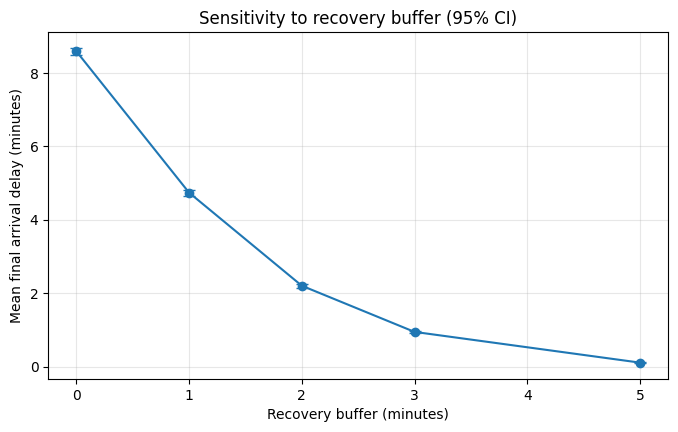

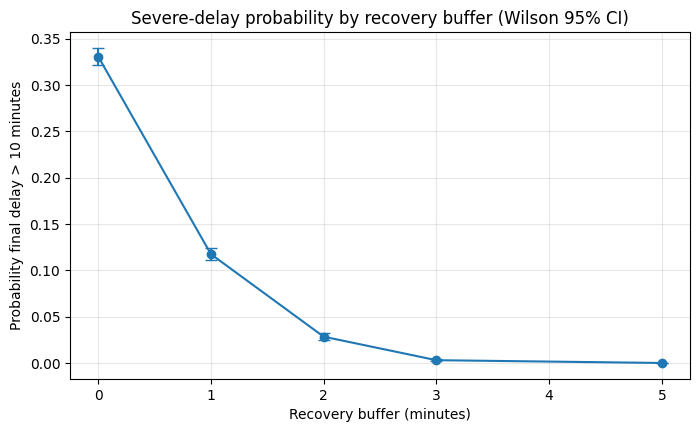

In [26]:
plt.figure(figsize=(8, 4.5))
means = buffer_df["Mean final delay (min)"].to_numpy()
low = buffer_df["Mean CI low"].to_numpy()
high = buffer_df["Mean CI high"].to_numpy()
plt.errorbar(buffer_df["Recovery buffer (min)"], means,
             yerr=[means-low, high-means], marker="o", capsize=4)
plt.xlabel("Recovery buffer (minutes)")
plt.ylabel("Mean final arrival delay (minutes)")
plt.title("Sensitivity to recovery buffer (95% CI)")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8, 4.5))
p = buffer_df["P(final delay > 10 min)"].to_numpy()
lo = buffer_df["P CI low"].to_numpy()
hi = buffer_df["P CI high"].to_numpy()
plt.errorbar(buffer_df["Recovery buffer (min)"], p,
             yerr=[p-lo, hi-p], marker="o", capsize=4)
plt.xlabel("Recovery buffer (minutes)")
plt.ylabel("Probability final delay > 10 minutes")
plt.title("Severe-delay probability by recovery buffer (Wilson 95% CI)")
plt.grid(True, alpha=0.3)
plt.show()

### 6.3 Initial-delay sensitivity analysis
The initial delay is applied to every service at Maradana in each scenario. This represents a controlled stress test of a delayed start, not a measured event. The scenarios compare 0, 5 and 10 minute initial delays while holding the recovery buffer at 2 minutes.

,Initial delay (min),Mean final delay (min),Mean CI low,Mean CI high,P(final delay > 10 min),P CI low,P CI high
0,0.0,2.180,2.122,2.238,0.027,0.024,0.031
1,5.0,4.038,3.958,4.118,0.103,0.097,0.109
2,10.0,8.380,8.289,8.472,0.324,0.314,0.333


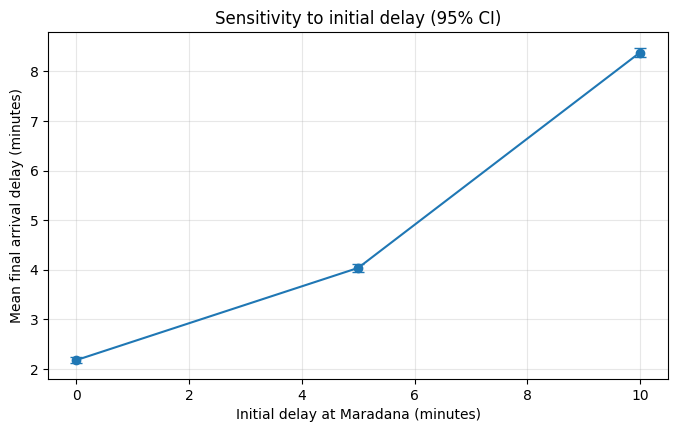

In [27]:
initial_sensitivity = []
for j, init_delay in enumerate([0.0, 5.0, 10.0]):
    res = monte_carlo(
        N_REPLICATIONS,
        recovery_buffer=2.0,
        initial_delay=init_delay,
        seed=MASTER_SEED + 300 + j,
    )
    initial_sensitivity.append({
        "Initial delay (min)": init_delay,
        "Mean final delay (min)": res["mean_delay"],
        "Mean CI low": res["mean_ci_low"],
        "Mean CI high": res["mean_ci_high"],
        "P(final delay > 10 min)": res["p_over_10"],
        "P CI low": res["p_ci_low"],
        "P CI high": res["p_ci_high"],
    })
initial_df = pd.DataFrame(initial_sensitivity)
display(initial_df.round(3))

plt.figure(figsize=(8, 4.5))
m = initial_df["Mean final delay (min)"].to_numpy()
lo = initial_df["Mean CI low"].to_numpy()
hi = initial_df["Mean CI high"].to_numpy()
plt.errorbar(initial_df["Initial delay (min)"], m,
             yerr=[m-lo, hi-m], marker="o", capsize=4)
plt.xlabel("Initial delay at Maradana (minutes)")
plt.ylabel("Mean final arrival delay (minutes)")
plt.title("Sensitivity to initial delay (95% CI)")
plt.grid(True, alpha=0.3)
plt.show()

### 6.4 Comparison with operational context (X4-limitation)
The Monte Carlo severe-delay probability is a result from this assumed model. Compare it descriptively with official system-wide figures, but do not claim equality or calibration: the definitions, population, route coverage, time period and data resolution differ. Route-specific calibration would require train-level actual arrival/departure records for these services.

In [28]:
comparison = pd.DataFrame([
    {
        "Measure": "Model P(final arrival delay > 10 min)",
        "Estimate": baseline_mc["p_over_10"],
        "Evidence type": "Synthetic Monte Carlo output; assumptions-based",
    },
    {
        "Measure": "Sri Lanka Railways 2023: reported over-10-minute category",
        "Estimate": 0.5162,
        "Evidence type": "Published system-wide aggregate; not route-specific",
    },
    {
        "Measure": "Auditor General 2024: operated services delayed 10–60 min",
        "Estimate": 0.49,
        "Evidence type": "Published system-wide aggregate; not route-specific",
    },
])
display(comparison)

,Measure,Estimate,Evidence type
0,Model P(final arrival delay > 10 min),0.0273,Synthetic Monte Carlo output; assumptions-based
1,Sri Lanka Railways 2023: reported over-10-minu...,0.5162,Published system-wide aggregate; not route-spe...
2,Auditor General 2024: operated services delaye...,0.4900,Published system-wide aggregate; not route-spe...


### 6.5 Summary of experimental outputs
The tables and plots above report the baseline estimates, sensitivity results and confidence intervals. Use the latest outputs generated by running all cells when writing the report.

## **7. Discussion and limitations**




### 7.1 Discussion of results

1. **Effect of recovery buffer:** As the recovery buffer increases, the mean final arrival delay decreases. This indicates that a larger recovery buffer helps reduce delay propagation between stations.

2. **Probability of delays greater than 10 minutes:** The probability of final delays exceeding $10$ minutes decreases as the recovery buffer increases. This shows that recovery buffers can reduce the risk of significant delays.

3. **Monte Carlo uncertainty:** The 95% confidence intervals are relatively narrow, indicating low sampling uncertainty in the estimated mean delays and probabilities. The 2,000 Monte Carlo replications provide reasonably consistent results under the assumed model parameters.

4. **Effect of initial delay:** Increasing the initial delay at Maradana increases the mean final arrival delay and the probability of delays exceeding $10$ minutes. This shows that initial disruptions can propagate through the railway line and affect later services.

5. **X2 is addressed through:** stochastic-matrix, empirical transition-frequency, deterministic-limit and headway tests.

6. **X4 is addressed through:** timetable-based input and official system-wide operational context, with a clear statement that true route-level calibration requires granular data.

7. **X5 is addressed through:** buffer and initial-delay sensitivity experiments with confidence intervals.

**Overall finding:** The experiments demonstrate that recovery buffers help reduce delay propagation, while initial delays increase the risk of significant delays. The confidence intervals also help assess the reliability of the Monte Carlo estimates under the assumed conditions.

### 7.2 Limitations and next steps


- Only six common stations are modelled. Several timetables contain additional stops; skipping those stops means the model is a corridor-level abstraction.
- The Markov transition matrix, regime shocks, running-time noise, dwell-time distribution and minimum headway are assumptions.
- Aggregate punctuality reports cannot identify route-specific Markov transitions or dwell-time distributions.
- The model does not include track occupancy, signalling blocks, overtaking, cancellations, rolling-stock constraints or detailed railway dispatching.

## **8. References**

[1] Sri Lanka Railways, *Administration Report 2023*, Transportation / punctuality statistics. https://railway.gov.lk/web/images/pdf/admin%20report_2023.pdf

[2] Auditor General's Department, Sri Lanka, *Annual Report 2024*, “Cancellation of Train Services and Delays.” https://auditorgeneral.gov.lk/web/images/audit-reports/upload/2024/Annual_Report/Annual-Report-2024-English-Web_compressed.pdf

[3] Sri Lanka Railways, “Revised Train Timetable from 2025/12/02 onward (Until Further Notice),” Coastal Line timetable notice. https://www.railway.gov.lk/web/images/news/2025-12-02%20all%20eng.pdf

[4] Five Maradana → Panadura train schedules (weekday services), supplied timetable screenshots in data/train_timetables folder. https://github.com/Nadil-Dulran/train-delay-propagation-simulation
